# EMQA_L2_battery

**Case study (d): economic value of a more accurate forecast**

Energy Markets Quantitative Analysis (EMQA), Lecture 2 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L2/EMQA_L2_battery/EMQA_L2_battery.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# course chart style: transparent background, no grid, legend at the bottom outside the axes
plt.rcParams.update({
    "figure.facecolor": "none", "axes.facecolor": "none", "savefig.transparent": True,
    "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#222222", "axes.labelcolor": "#222222", "xtick.color": "#222222", "ytick.color": "#222222",
    "text.color": "#222222", "font.size": 11, "axes.titlesize": 11.5, "axes.labelsize": 11,
    "legend.fontsize": 10.5, "legend.frameon": False, "lines.linewidth": 1.4, "font.family": "DejaVu Sans"})
PAL = {"RO": "#2a78d6", "DE_LU": "#eb6834", "HU": "#1baf7a", "BG": "#eda100",
       "c5": "#e87ba4", "c6": "#008300", "c7": "#6250d6", "c8": "#e34948"}   # fixed colour per entity


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for hh, ll in zip(*ax.get_legend_handles_labels()):
                if ll not in labels:
                    handles.append(hh)
                    labels.append(ll)
    if handles:
        fig.legend(handles, labels, loc="lower center", ncol=ncol, bbox_to_anchor=(0.5, y),
                   frameon=False, handlelength=2.0, columnspacing=1.2)

## Data and cut-off

In [3]:
TZ = "Europe/Brussels"
PD = pd.read_csv(DATA + "power_da_prices_daily_cet.csv", parse_dates=["date_cet"]).set_index("date_cet")
_hydro = pd.read_csv(DATA + "generation_ro_mw_daily_cet.csv", usecols=["date_cet", "hydro_run_of_river"],
                     parse_dates=["date_cet"]).set_index("date_cet")["hydro_run_of_river"]
# cut-off = last complete month covered by the prices and the Romanian generation data
_raw_last = min(PD["RO"].dropna().index.max(), _hydro.dropna().index.max())
END = pd.Timestamp(((_raw_last + pd.Timedelta(days=1)).to_period("M").to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp("2022-01-01")
N_TEST, N_BURN = 365, 182                                  # test year; burn-in (its forecasts only feed QRA, CP, HS)
TEST0 = END - pd.Timedelta(days=N_TEST - 1)
FC0 = TEST0 - pd.Timedelta(days=N_BURN)
FDAYS = pd.date_range(FC0, END, freq="D")                  # burn-in + test days
TDAYS = pd.date_range(TEST0, END, freq="D")                # test days
print("cut-off:", END.date(), "| test year:", TEST0.date(), "to", END.date())

cut-off: 2026-10-31 | test year: 2025-11-01 to 2026-10-31


## Panels of price, load and wind + solar

In [4]:
def day_matrix(s):
    """UTC-indexed hourly series -> CET delivery day x 24 hours (Assignment 1 / epftoolbox DST convention) + DST flag."""
    s = s.copy()
    s.index = pd.to_datetime(s.index, utc=True).tz_convert(TZ)
    df = pd.DataFrame({"v": s.values, "day": s.index.tz_localize(None).normalize(), "h": s.index.hour})
    m = df.groupby(["day", "h"])["v"].mean().unstack("h").reindex(columns=range(24))     # 25-h day: doubled hour averaged
    days = m.index
    nh = ((((days + pd.Timedelta(days=1)).tz_localize(TZ)) - days.tz_localize(TZ)) / pd.Timedelta(hours=1)).astype(int)
    dst = pd.Series(np.asarray(nh != 24), index=days)
    for dd in days[dst.values]:
        if pd.isna(m.loc[dd, 2]):
            m.loc[dd, 2] = 0.5 * (m.loc[dd, 1] + m.loc[dd, 3])                              # 23-h day: h02 = mean(h01, h03)
    m = m.dropna(how="any")
    return m, dst.reindex(m.index)


HP = pd.read_csv(DATA + "power_da_prices_hourly_utc.csv", index_col=0, usecols=["timestamp_utc", "RO"])
PM, DST = day_matrix(HP["RO"].dropna())
CAL = pd.date_range(START, END, freq="D")
PM, DST = PM.reindex(CAL), DST.reindex(CAL)
GH = pd.read_csv(DATA + "generation_ro_mw_hourly_utc.csv", index_col=0, usecols=["timestamp_utc", "load", "wind_onshore", "solar"])
LM, _ = day_matrix(GH["load"].dropna())
RM, _ = day_matrix((GH["wind_onshore"] + GH["solar"]).dropna())
LM, RM = LM.reindex(CAL), RM.reindex(CAL)
assert not PM.isna().any().any() and not LM.isna().any().any() and not RM.isna().any().any(), "panel has gaps"
L_, R_ = LM.values.astype(float), RM.values.astype(float)
P_ = PM.values.astype(float)
DOW = CAL.dayofweek.values
IDX = {t: i for i, t in enumerate(CAL)}
TI_ROWS = np.array([IDX[t] for t in TDAYS])              # panel rows of the test days
A = P_[TI_ROWS]                                          # actual prices of the test year, days x 24
# naive benchmark: same hour of d-7 on Monday, Saturday, Sunday, of d-1 otherwise
NAIVE = np.array([P_[i - 7] if DOW[i] in (0, 5, 6) else P_[i - 1] for i in TI_ROWS])
print("panel:", CAL[0].date(), "to", CAL[-1].date(), len(CAL), "days x 24 hours")

panel: 2022-01-01 to 2026-10-31 1765 days x 24 hours


## Expert ARX forecasts

The expert ARX model (one OLS regression per hour, Assignment 1 specification) is cheap and is recomputed here for the six calibration windows 56, 84, 112, 714, 721 and 728 days; AW-ARX is their average.

In [5]:
from scipy import stats


def shift_rows(A, k):
    out = np.full_like(A, np.nan)
    out[k:] = A[:-k]
    return out


def mad_scale(x):
    x = np.asarray(x, float).ravel()
    m = np.median(x)
    s = stats.median_abs_deviation(x, scale="normal")
    return m, (s if s > 0 else 1.0)


def arx_day(Pa, La, Ra, Fa, i, T, kind="asinh"):
    """Expert ARX (Assignment 1, Ziel & Weron 2018 style), one regression per hour; target day = row i.
    Calibration targets rows i-T..i-1; VST median/MAD from price rows i-T-7..i-1; L,R z-scores from rows i-T-7..i-2."""
    P1, P2, P7 = shift_rows(Pa, 1), shift_rows(Pa, 2), shift_rows(Pa, 7)
    lo = i - T
    if kind == "raw":
        m, s = 0.0, 1.0
        f = lambda x: x  # noqa: E731
        finv = f
    else:
        m, s = mad_scale(Pa[lo - 7:i])
        f = lambda x: np.arcsinh((x - m) / s)  # noqa: E731
        finv = lambda y: m + s * np.sinh(y)  # noqa: E731
    rows = slice(lo, i + 1)
    Y, Y1, Y2, Y7 = f(Pa[rows]), f(P1[rows]), f(P2[rows]), f(P7[rows])
    mu_l, sd_l = np.mean(La[lo - 7:i - 1]), np.std(La[lo - 7:i - 1])
    mu_r, sd_r = np.mean(Ra[lo - 7:i - 1]), np.std(Ra[lo - 7:i - 1])
    Lz = (shift_rows(La, 2)[rows] - mu_l) / sd_l
    Rz = (shift_rows(Ra, 2)[rows] - mu_r) / sd_r
    dw = DOW[rows]
    dmy = np.column_stack([dw == 0, dw == 5, dw == 6]).astype(float)
    extra = None
    if kind == "fund":
        Fr = Fa[rows]
        extra = (Fr - np.nanmean(Fr[:-1], axis=0)) / np.nanstd(Fr[:-1], axis=0)
    n = T + 1
    out, coefs = np.zeros(24), np.zeros((24, 12))
    if kind == "single":                                          # one pooled regression, common slopes, hour intercepts
        Xs, ys = [], []
        for h in range(24):
            hd = np.zeros((n, 24))
            hd[:, h] = 1
            Xs.append(np.column_stack([hd, Y1[:, h], Y2[:, h], Y7[:, h], Y1[:, 23], Y1.min(1), Y1.max(1), Lz[:, h], Rz[:, h], dmy]))
            ys.append(Y[:, h])
        Xs, ys = np.stack(Xs, 1), np.stack(ys, 1)                 # n x 24 x p
        Xc, yc = Xs[:-1].reshape(-1, Xs.shape[2]), ys[:-1].ravel()
        b = np.linalg.lstsq(Xc, yc, rcond=None)[0]
        return finv(Xs[-1] @ b), None
    for h in range(24):
        cols = [np.ones(n), Y1[:, h], Y2[:, h], Y7[:, h], Y1[:, 23], Y1.min(1), Y1.max(1)]
        if kind != "noexog":
            cols += [Lz[:, h], Rz[:, h]]
        cols += [dmy[:, 0], dmy[:, 1], dmy[:, 2]]
        X = np.column_stack(cols)
        if h == 23:
            X = np.delete(X, 4, axis=1)                           # Y_{d-1,23} appears twice for h = 23
        if extra is not None:
            X = np.column_stack([X, extra])
        b = np.linalg.lstsq(X[:-1], Y[:-1, h], rcond=None)[0]
        out[h] = X[-1] @ b
        if kind == "asinh" and h != 23 and X.shape[1] == 12:
            coefs[h] = b
    return finv(out), coefs

In [6]:
ARX_W = (56, 84, 112, 714, 721, 728)                     # calibration windows (days)
# one forecast per test day and window, re-estimated every day (a few seconds)
ARX = {T: np.array([arx_day(P_, L_, R_, None, i, T)[0] for i in TI_ROWS]) for T in ARX_W}
AW_ARX = np.mean([ARX[T] for T in ARX_W], 0)            # average across windows
print("ARX ready")

ARX ready


## Forecasts

LEAR (LASSO-estimated autoregression, 247 candidate regressors, $\lambda$ by AIC) is re-estimated every day for each hour and for the windows 364, 546 and 728 days; AW-LEAR is the average across the three windows. This takes about 2.5 s per day and window, so the forecasts computed by `lectures/L2/analysis_L2.py` are loaded from the file saved next to this notebook. Set `RUN_ALL = True` to recompute them with the code below. GBM (gradient boosting) and MLP (a 24-output neural network, 4 seeds) are refitted every month on an expanding window that ends before the month.

In [7]:
RUN_ALL = False   # True: recompute the forecasts from the data (LEAR roughly 45 min, GBM and MLP roughly 10 min on one core; joblib uses all cores)

QL = REPO + "Quantlets/L2/EMQA_L2_battery/"          # saved results of this Quantlet


def load_npz(path):
    if path.startswith("http"):
        import io
        import urllib.request
        return np.load(io.BytesIO(urllib.request.urlopen(path).read()))
    return np.load(path)


def load_csv(name, days):
    S = pd.read_csv(QL + name, parse_dates=["date"], float_precision="round_trip")
    assert (pd.DatetimeIndex(S["date"].drop_duplicates()) == days).all()
    return S


PLAGS, XLAGS = (1, 2, 3, 7), (2, 3, 7)                   # price lags; lags of load and wind+solar (days)
LEAR_W = (364, 546, 728)


def lear_design(Pa, La, Ra, lo, i):
    """LEAR regressors (Assignment 1: 247 columns) for rows lo..i, with transforms fitted on rows available at gate closure."""
    m, s = mad_scale(Pa[lo - 7:i])
    mL, sL = mad_scale(La[lo - 7:i - 1])
    mR, sR = mad_scale(Ra[lo - 7:i - 1])
    rows = slice(lo, i + 1)
    blocks = [np.arcsinh((shift_rows(Pa, k)[rows] - m) / s) for k in PLAGS]
    blocks += [np.arcsinh((shift_rows(La, k)[rows] - mL) / sL) for k in XLAGS]
    blocks += [np.arcsinh((shift_rows(Ra, k)[rows] - mR) / sR) for k in XLAGS]
    blocks.append(np.eye(7)[DOW[rows]])
    X = np.column_stack(blocks)
    Y = np.arcsinh((Pa[rows] - m) / s)
    return X, Y, m, s


def lear_day(Pa, La, Ra, i, T):
    from sklearn.linear_model import LassoLarsIC
    lo = i - T
    X, Y, m, s = lear_design(Pa, La, Ra, lo, i)
    mu, sd = X[:-1].mean(0), X[:-1].std(0)
    sd[sd == 0] = 1.0
    Xs = (X - mu) / sd
    out, nz = np.zeros(24), np.zeros((24, X.shape[1]), bool)
    for h in range(24):
        mdl = LassoLarsIC(criterion="aic", max_iter=2000).fit(Xs[:-1], Y[:-1, h])
        out[h] = mdl.predict(Xs[-1:])[0]
        nz[h] = mdl.coef_ != 0
    return m + s * np.sinh(out), nz


SEED = 20261105
GBM_NAMES = ["P(d-1,h)", "P(d-2,h)", "P(d-3,h)", "P(d-7,h)", "P(d-1,23)", "min P(d-1)", "max P(d-1)", "mean P(d-1)",
             "L(d-2,h)", "L(d-7,h)", "RES(d-2,h)", "RES(d-7,h)", "mean L(d-2)", "mean RES(d-2)", "hydro(d-2)", "nuclear(d-2)",
             "net imports(d-2)", "EUA(d-2)", "hour", "day of week"]


def gbm_rows(Pa, La, Ra, Fa, rows):
    """Long-format features for (day, hour) pairs: same-hour lags, daily aggregates, fundamentals, calendar."""
    P1, P2, P3, P7 = (shift_rows(Pa, k) for k in PLAGS)
    L2, L7, R2, R7 = shift_rows(La, 2), shift_rows(La, 7), shift_rows(Ra, 2), shift_rows(Ra, 7)
    feats = []
    for h in range(24):
        f = np.column_stack([P1[rows, h], P2[rows, h], P3[rows, h], P7[rows, h], P1[rows, 23], P1[rows].min(1), P1[rows].max(1),
                             P1[rows].mean(1), L2[rows, h], L7[rows, h], R2[rows, h], R7[rows, h], L2[rows].mean(1),
                             R2[rows].mean(1), Fa[rows], np.full(len(rows), h), DOW[rows]])
        feats.append(f)
    return np.stack(feats, 1)


def gbm_month(Pa, La, Ra, Fa, i0, i1, seed=SEED):
    """Fit on targets rows 7..i0-1 (all before the month), forecast rows i0..i1 (the month)."""
    from sklearn.ensemble import HistGradientBoostingRegressor
    tr = np.arange(7, i0)
    m, s = mad_scale(Pa[tr])
    Xtr = gbm_rows(Pa, La, Ra, Fa, tr).reshape(-1, len(GBM_NAMES))
    ytr = np.arcsinh((Pa[tr] - m) / s).ravel()
    mdl = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=40,
                                        l2_regularization=1.0, early_stopping=False, random_state=seed,
                                        categorical_features=[18, 19]).fit(Xtr, ytr)
    te = np.arange(i0, i1 + 1)
    pr = mdl.predict(gbm_rows(Pa, La, Ra, Fa, te).reshape(-1, len(GBM_NAMES))).reshape(len(te), 24)
    return m + s * np.sinh(pr), mdl


def mlp_design(Pa, La, Ra, Fa, rows, m, s, mL, sL, mR, sR):
    blocks = [np.arcsinh((shift_rows(Pa, k)[rows] - m) / s) for k in PLAGS]
    blocks += [np.arcsinh((shift_rows(La, k)[rows] - mL) / sL) for k in XLAGS]
    blocks += [np.arcsinh((shift_rows(Ra, k)[rows] - mR) / sR) for k in XLAGS]
    blocks += [Fa[rows], np.eye(7)[DOW[rows]]]
    return np.column_stack(blocks)


def mlp_month(Pa, La, Ra, Fa, i0, i1, seeds=(1, 2, 3, 4), max_ep=150):
    """Multi-output network (24 outputs, Lago et al. 2021 style DNN, small). Epochs chosen on a CHRONOLOGICAL validation
    block (last 15% of the training days); then refitted on all training days with that number of epochs."""
    from sklearn.neural_network import MLPRegressor
    tr = np.arange(7, i0)
    cut = int(len(tr) * 0.85)
    v0 = tr[cut]                                                # first validation day: transforms frozen at its gate closure
    m0, s0 = mad_scale(Pa[7:v0])
    mL0, sL0 = mad_scale(La[7:v0 - 1])
    mR0, sR0 = mad_scale(Ra[7:v0 - 1])
    X0 = mlp_design(Pa, La, Ra, Fa, tr, m0, s0, mL0, sL0, mR0, sR0)
    Y0 = np.arcsinh((Pa[tr] - m0) / s0)
    m, s = mad_scale(Pa[tr])                                    # final refit: everything available before the month
    mL, sL = mad_scale(La[7:i0 - 1])
    mR, sR = mad_scale(Ra[7:i0 - 1])
    X = mlp_design(Pa, La, Ra, Fa, tr, m, s, mL, sL, mR, sR)
    Y = np.arcsinh((Pa[tr] - m) / s)
    te = np.arange(i0, i1 + 1)
    Xte = mlp_design(Pa, La, Ra, Fa, te, m, s, mL, sL, mR, sR)
    preds, epochs = [], []
    for sd in seeds:
        mu, sg = X0[:cut].mean(0), X0[:cut].std(0)
        sg[sg == 0] = 1
        net = MLPRegressor(hidden_layer_sizes=(128, 64), alpha=1e-3, learning_rate_init=1e-3, batch_size=64, random_state=sd)
        best, best_ep = np.inf, 1
        for ep_ in range(1, max_ep + 1):
            net.partial_fit((X0[:cut] - mu) / sg, Y0[:cut])
            v = np.mean(np.abs(m0 + s0 * np.sinh(net.predict((X0[cut:] - mu) / sg)) - Pa[tr[cut:]]))
            if v < best:
                best, best_ep = v, ep_
        mu, sg = X.mean(0), X.std(0)
        sg[sg == 0] = 1
        net = MLPRegressor(hidden_layer_sizes=(128, 64), alpha=1e-3, learning_rate_init=1e-3, batch_size=64, random_state=sd)
        for _ in range(best_ep):
            net.partial_fit((X - mu) / sg, Y)
        preds.append(m + s * np.sinh(net.predict((Xte - mu) / sg)))
        epochs.append(best_ep)
    return np.mean(preds, 0), epochs


def month_blocks(days):
    out = []
    for _, g in pd.Series(days, index=days).groupby(days.to_period("M")):
        out.append((IDX[g.index[0]], IDX[g.index[-1]]))
    return out


if RUN_ALL:
    from joblib import Parallel, delayed
    _r = Parallel(n_jobs=-1)(delayed(lear_day)(P_, L_, R_, i, T) for T in LEAR_W for i in TI_ROWS)
    _n = len(TI_ROWS)
    LEAR = {T: np.array([r[0] for r in _r[k * _n:(k + 1) * _n]]) for k, T in enumerate(LEAR_W)}
    # daily fundamentals, value usable for day d = last observation on or before d-2 (past only)
    G = pd.read_csv(DATA + "generation_ro_mw_daily_cet.csv", parse_dates=["date_cet"]).set_index("date_cet")
    CB = pd.read_csv(DATA + "crossborder_ro_mw_daily_cet.csv", parse_dates=["date_cet"]).set_index("date_cet")
    EUA = pd.read_csv(DATA + "eua_daily.csv", parse_dates=["date"]).set_index("date")["eua_etc_co2l_eur_per_unit"]
    CAL_EX = pd.date_range(START - pd.Timedelta(days=30), END, freq="D")
    FUND_RAW = pd.DataFrame({"hydro": (G["hydro_run_of_river"] + G["hydro_water_reservoir"]).reindex(CAL_EX),
                             "nuclear": G["nuclear"].reindex(CAL_EX), "netimp": CB["sum"].reindex(CAL_EX),
                             "eua": EUA.reindex(CAL_EX)})
    F_ = FUND_RAW.ffill().shift(2).reindex(CAL).values.astype(float)
    MB = month_blocks(TDAYS)                                # monthly refits on an expanding window
    GBM = np.vstack([g[0] for g in Parallel(n_jobs=-1)(delayed(gbm_month)(P_, L_, R_, F_, a, b) for a, b in MB)])
    MLP = np.vstack([m[0] for m in Parallel(n_jobs=-1)(delayed(mlp_month)(P_, L_, R_, F_, a, b) for a, b in MB)])
else:
    S = load_csv("forecasts_test.csv", TDAYS)
    LEAR = {T: S[f"lear{T}"].values.reshape(-1, 24) for T in LEAR_W}
    GBM, MLP = S["gbm"].values.reshape(-1, 24), S["mlp"].values.reshape(-1, 24)
AW_LEAR = np.mean([LEAR[T] for T in LEAR_W], 0)
ENS_ALL = np.mean([AW_ARX, AW_LEAR, GBM, MLP], 0)         # equal-weight ensemble of the four models
for k, v in [("AW-ARX", AW_ARX), ("AW-LEAR", AW_LEAR), ("GBM", GBM), ("MLP", MLP), ("Ens. 4 models", ENS_ALL)]:
    print(f"{k:14s} MAE {np.mean(np.abs(A - v)):.2f} EUR/MWh")

AW-ARX         MAE 22.30 EUR/MWh
AW-LEAR        MAE 22.53 EUR/MWh
GBM            MAE 24.05 EUR/MWh
MLP            MAE 25.54 EUR/MWh
Ens. 4 models  MAE 22.13 EUR/MWh


## Battery and flexible consumer, valued at the actual prices (days with a clock change left out)

In [8]:
def battery(F, Aa, eta=0.9):
    """1 MW / 2 MWh battery, one cycle a day: charge in a 2-hour block, discharge in a later 2-hour block, both chosen on the
    forecast; trade only if the forecast spread pays the losses. Profit in EUR, valued at actual prices."""
    prof = np.zeros(len(F))
    for k in range(len(F)):
        f, a = F[k], Aa[k]
        bestv, bs = 0.0, None
        for i in range(0, 21):
            for j in range(i + 2, 23):
                v = eta * (f[j] + f[j + 1]) - (f[i] + f[i + 1])
                if v > bestv:
                    bestv, bs = v, (i, j)
        if bs:
            i, j = bs
            prof[k] = eta * (a[j] + a[j + 1]) - (a[i] + a[i + 1])
    return prof


def flex(F, Aa, L=4, fixed=8):
    """Flexible process of 1 MW for L consecutive hours a day: start chosen on the forecast; cost in EUR at actual prices."""
    cost, base = np.zeros(len(F)), np.zeros(len(F))
    for k in range(len(F)):
        s = int(np.argmin([F[k][i:i + L].sum() for i in range(24 - L + 1)]))
        cost[k] = Aa[k][s:s + L].sum()
        base[k] = Aa[k][fixed:fixed + L].sum()
    return cost, base


NODST = ~DST.loc[TDAYS].values
AN = A[NODST]
M = {"naive": NAIVE, "aw_arx": AW_ARX, "aw_lear": AW_LEAR, "gbm": GBM, "ens_all": ENS_ALL}
BAT = {k: battery(v[NODST], AN) for k, v in M.items()}
BAT["perfect"] = battery(AN, AN)
FLX = {k: flex(v[NODST], AN)[0] for k, v in M.items()}
FLX["perfect"], FLX_BASE = flex(AN, AN)
print(pd.DataFrame({"battery, EUR": {k: v.sum() for k, v in BAT.items()},
                    "flexible buyer, EUR/MWh": {k: v.sum() / (4 * len(v)) for k, v in FLX.items()}}).round(2).to_string())

         battery, EUR  flexible buyer, EUR/MWh
naive        84622.68                    71.74
aw_arx       88776.13                    68.67
aw_lear      89567.84                    67.87
gbm          89184.30                    68.93
ens_all      90738.14                    68.09
perfect      99698.32                    64.82


## The chart

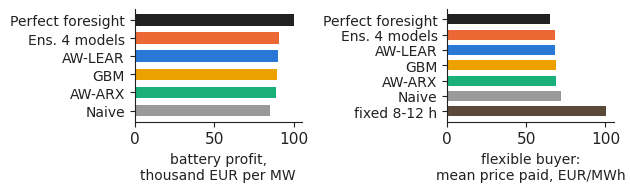

In [9]:
COL = {"naive": "#9a9a9a", "aw_arx": PAL["HU"], "aw_lear": PAL["RO"], "gbm": PAL["BG"], "ens_all": PAL["DE_LU"], "perfect": "#222222"}
LAB = {"naive": "Naive", "aw_arx": "AW-ARX", "aw_lear": "AW-LEAR", "gbm": "GBM", "ens_all": "Ens. 4 models", "perfect": "Perfect foresight"}
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.1))
kb = ["perfect", "ens_all", "aw_lear", "gbm", "aw_arx", "naive"]
axs[0].barh(range(len(kb)), [BAT[k].sum() / 1000 for k in kb], color=[COL[k] for k in kb], height=0.65)
axs[0].set_yticks(range(len(kb)))
axs[0].set_yticklabels([LAB[k] for k in kb], fontsize=10)
axs[0].invert_yaxis()
axs[0].set_xlabel("battery profit,\nthousand EUR per MW", fontsize=10)
vf = [FLX[k].sum() / (4 * len(FLX[k])) for k in kb] + [FLX_BASE.sum() / (4 * len(FLX_BASE))]
axs[1].barh(range(len(vf)), vf, color=[COL[k] for k in kb] + ["#5b4a3a"], height=0.65)
axs[1].set_yticks(range(len(vf)))
axs[1].set_yticklabels([LAB[k] for k in kb] + ["fixed 8-12 h"], fontsize=10)
axs[1].invert_yaxis()
axs[1].set_xlabel("flexible buyer:\nmean price paid, EUR/MWh", fontsize=10)
fig.tight_layout(rect=(0, 0.02, 1, 1))
plt.savefig('battery.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()

In [10]:
print("Numbers on the slide")
print(f'  days without a clock change: {int(NODST.sum()):d}')
print(f'  battery profit with the ensemble, EUR per MW: {BAT["ens_all"].sum():.0f}')
print(f'  share of perfect foresight, %: {BAT["ens_all"].sum() / BAT["perfect"].sum() * 100:.1f}')
print(f'  battery profit with naive, EUR per MW: {BAT["naive"].sum():.0f}')
print(f'  battery profit with perfect foresight, EUR per MW: {BAT["perfect"].sum():.0f}')
print(f'  flexible buyer with AW-LEAR, EUR/MWh: {FLX["aw_lear"].sum() / (4 * len(FLX["aw_lear"])):.2f}')
print(f'  fixed 8-12 h block, EUR/MWh: {FLX_BASE.sum() / (4 * len(FLX_BASE)):.2f}')

Numbers on the slide
  days without a clock change: 363
  battery profit with the ensemble, EUR per MW: 90738
  share of perfect foresight, %: 91.0
  battery profit with naive, EUR per MW: 84623
  battery profit with perfect foresight, EUR per MW: 99698
  flexible buyer with AW-LEAR, EUR/MWh: 67.87
  fixed 8-12 h block, EUR/MWh: 100.59
